# 🛒 BlinkIT Grocery Sales Analysis
### Domain: Retail & Grocery Sales Analytics | Company: Sapphire IQ
**Student Project by Data Analyst (Ram)**  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

---

## 📌 Executive Project Context
Ram has been assigned to analyze BlinkIT's grocery sales data across multiple outlet types, product categories, and geographical locations. The primary objective is to transform raw sales records into clear, reliable, and actionable business intelligence for executive decision-making.

### 🎯 Core Objectives:
1. **Objective 1:** Understand the Business and Its Sales Performance
2. **Objective 2:** Make Sure the Available Information Is Reliable (Data Cleaning & Quality)
3. **Objective 3:** Find Out What Is Driving Better Sales Performance
4. **Objective 4:** Help Management Make Better Business Decisions
5. **Graphical Representations Suite:** Comprehensive Pie Charts, Circular Donut Charts, and Bar Charts


In [1]:
# Import Core Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Visualization Settings
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


---
## 📥 Step 0: Data Loading & Initial Inspection
We load the raw dataset provided by Sapphire IQ and inspect its structure, dimensions, and initial preview.


In [2]:
# Load the dataset
data_path = os.path.join('..', 'data', 'raw', 'BlinkIT_Grocery_Data.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'raw', 'BlinkIT_Grocery_Data.csv')

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]:,d} rows × {df.shape[1]} columns")
df.head(5)


Dataset Shape: 8,523 rows × 12 columns


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


---
## 🔍 Objective 1: Understand the Business and Its Sales Performance

### 📋 Task 1.1: Understand what types of products BlinkIT is selling
We examine all 16 unique product categories, their product counts, and share of total catalog inventory.


,Item Type,Item Count,Catalog Share (%)
0,Fruits and Vegetables,1232,14.455004
1,Snack Foods,1200,14.079549
2,Household,910,10.676992
3,Frozen Foods,856,10.043412
4,Dairy,682,8.001877
5,Canned,649,7.614690
6,Baking Goods,648,7.602957
7,Health and Hygiene,520,6.101138
8,Soft Drinks,445,5.221166
9,Meat,425,4.986507


C:\Users\sn740\AppData\Local\Temp\ipykernel_18908\3407004298.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_summary, x='Item Count', y='Item Type', palette='crest')


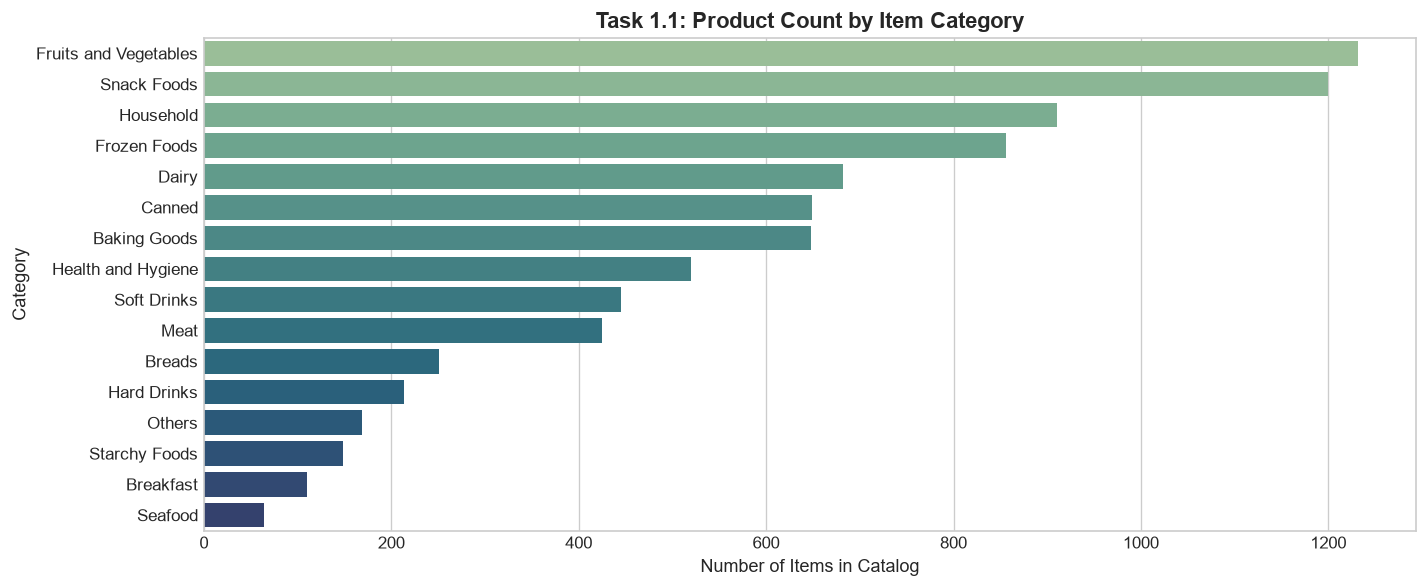

In [3]:
# Task 1.1: Product Types Breakdown
product_summary = df['Item Type'].value_counts().reset_index()
product_summary.columns = ['Item Type', 'Item Count']
product_summary['Catalog Share (%)'] = (product_summary['Item Count'] / len(df)) * 100
display(product_summary)

plt.figure(figsize=(12, 5))
sns.barplot(data=product_summary, x='Item Count', y='Item Type', palette='crest')
plt.title('Task 1.1: Product Count by Item Category')
plt.xlabel('Number of Items in Catalog')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


### 📋 Task 1.2: Understand the different types and locations of BlinkIT outlets
We profile the 10 distinct retail outlets, their format types, geographical location tiers, and store sizes.


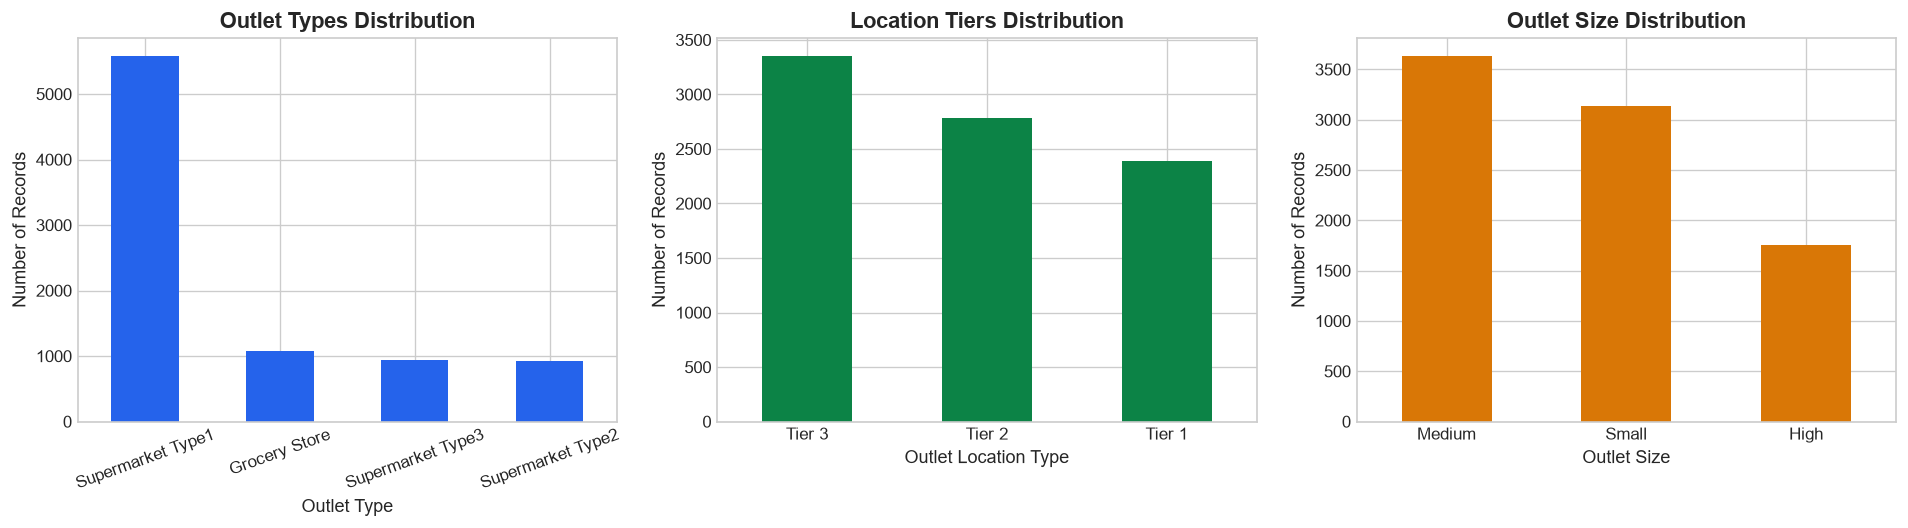

,Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Size,Outlet Establishment Year,Record Count
0,OUT010,Grocery Store,Tier 3,High,2011,233
1,OUT010,Grocery Store,Tier 3,Medium,2011,265
2,OUT010,Grocery Store,Tier 3,Small,2011,57
3,OUT013,Supermarket Type1,Tier 3,High,2014,932
4,OUT017,Supermarket Type1,Tier 2,High,2020,314
5,OUT017,Supermarket Type1,Tier 2,Medium,2020,244
6,OUT017,Supermarket Type1,Tier 2,Small,2020,368
7,OUT018,Supermarket Type2,Tier 3,Medium,2022,928
8,OUT019,Grocery Store,Tier 1,Small,2018,528
9,OUT027,Supermarket Type3,Tier 3,Medium,2018,935


In [4]:
# Task 1.2: Outlets, Formats & Geographical Tiers
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df['Outlet Type'].value_counts().plot(kind='bar', ax=axes[0], color='#2563EB', rot=20)
axes[0].set_title('Outlet Types Distribution')
axes[0].set_ylabel('Number of Records')

df['Outlet Location Type'].value_counts().plot(kind='bar', ax=axes[1], color='#0C8346', rot=0)
axes[1].set_title('Location Tiers Distribution')
axes[1].set_ylabel('Number of Records')

df['Outlet Size'].value_counts().plot(kind='bar', ax=axes[2], color='#D97706', rot=0)
axes[2].set_title('Outlet Size Distribution')
axes[2].set_ylabel('Number of Records')

plt.tight_layout()
plt.show()

outlet_meta = df.groupby(['Outlet Identifier', 'Outlet Type', 'Outlet Location Type', 'Outlet Size', 'Outlet Establishment Year']).size().reset_index(name='Record Count')
display(outlet_meta)


### 📋 Task 1.3: Understand how much BlinkIT is selling overall
We compute overall sales metrics: total gross revenue, average sales per item, median, standard deviation, and IQR.


Total Gross Sales ($)    : $1,201,681.49
Average Sales ($)        : $140.99
Median Sales ($)         : $143.01
Standard Deviation ($)   : $62.28
Min Sales ($)            : $31.29
Max Sales ($)            : $266.89
25th Percentile ($)      : $93.83
75th Percentile ($)      : $185.64


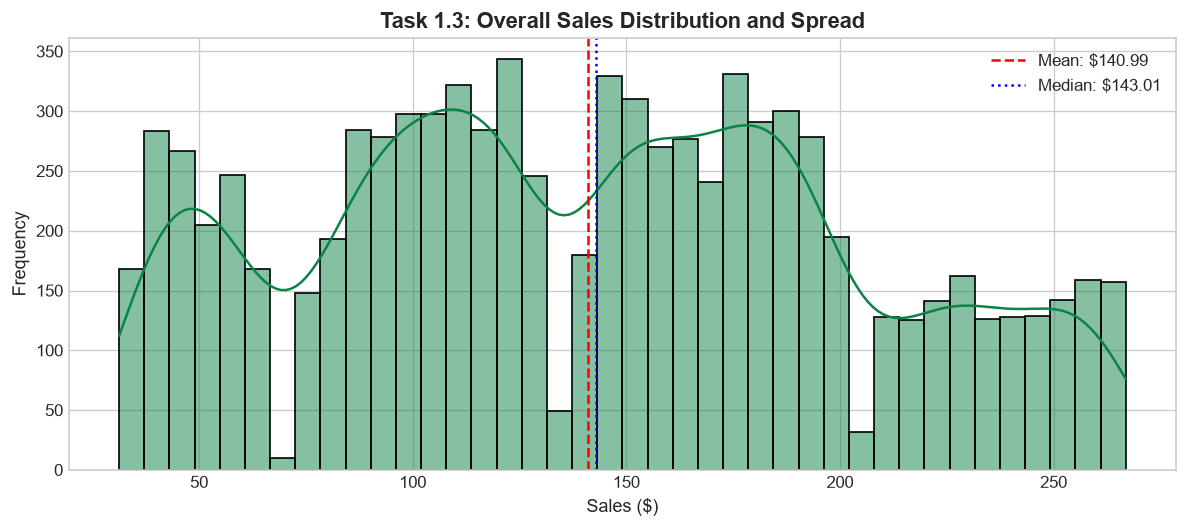

In [5]:
# Task 1.3: Overall Sales Statistics
sales_metrics = {
    'Total Gross Sales ($)': f"${df['Sales'].sum():,.2f}",
    'Average Sales ($)': f"${df['Sales'].mean():.2f}",
    'Median Sales ($)': f"${df['Sales'].median():.2f}",
    'Standard Deviation ($)': f"${df['Sales'].std():.2f}",
    'Min Sales ($)': f"${df['Sales'].min():.2f}",
    'Max Sales ($)': f"${df['Sales'].max():.2f}",
    '25th Percentile ($)': f"${df['Sales'].quantile(0.25):.2f}",
    '75th Percentile ($)': f"${df['Sales'].quantile(0.75):.2f}"
}
for k, v in sales_metrics.items():
    print(f"{k:<25}: {v}")

plt.figure(figsize=(10, 4.5))
sns.histplot(df['Sales'], kde=True, bins=40, color='#0C8346')
plt.axvline(df['Sales'].mean(), color='red', linestyle='--', label=f"Mean: ${df['Sales'].mean():.2f}")
plt.axvline(df['Sales'].median(), color='blue', linestyle=':', label=f"Median: ${df['Sales'].median():.2f}")
plt.title('Task 1.3: Overall Sales Distribution and Spread')
plt.xlabel('Sales ($)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()


### 📋 Task 1.4: Understand the overall customer rating and product performance
We analyze customer satisfaction ratings across the entire product catalog and outlet portfolio.


Overall Average Customer Rating: 3.97 / 5.0 (Std Dev: 0.61)


C:\Users\sn740\AppData\Local\Temp\ipykernel_18908\2715031764.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_by_type.values, y=rating_by_type.index, ax=axes[1], palette='flare')


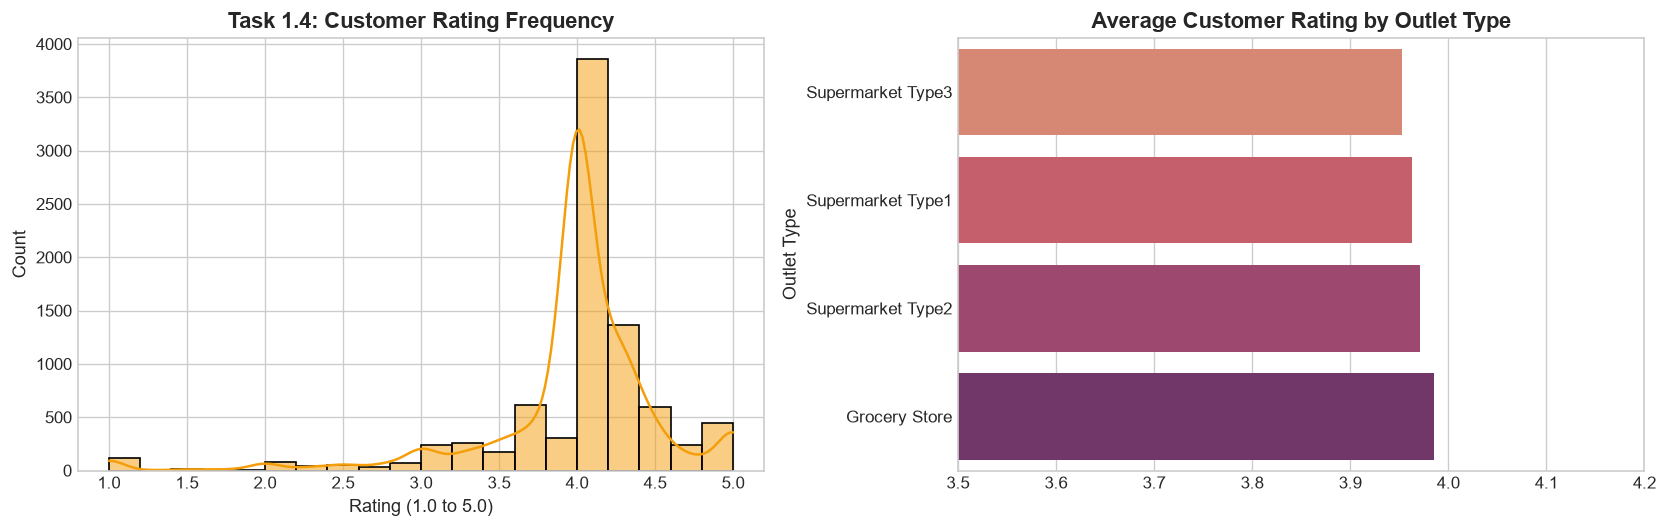

In [6]:
# Task 1.4: Customer Ratings Analysis
print(f"Overall Average Customer Rating: {df['Rating'].mean():.2f} / 5.0 (Std Dev: {df['Rating'].std():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df['Rating'], bins=20, ax=axes[0], color='#F59E0B', kde=True)
axes[0].set_title('Task 1.4: Customer Rating Frequency')
axes[0].set_xlabel('Rating (1.0 to 5.0)')

rating_by_type = df.groupby('Outlet Type')['Rating'].mean().sort_values()
sns.barplot(x=rating_by_type.values, y=rating_by_type.index, ax=axes[1], palette='flare')
axes[1].set_title('Average Customer Rating by Outlet Type')
axes[1].set_xlim(3.5, 4.2)
plt.tight_layout()
plt.show()


---
## 🛠️ Objective 2: Make Sure the Available Information Is Reliable (Data Cleaning)

### 📋 Task 2.1: Find information that is missing from the available records
We audit missing values and implement a rigorous 2-stage imputation for `Item Weight`.


In [7]:
# Task 2.1: Missing Value Audit & Imputation
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_df[missing_df['Missing Count'] > 0])

# Impute Item Weight: 1. By Item Identifier mean, 2. By Item Type mean fallback
clean_df = df.copy()
item_weight_map = clean_df.dropna(subset=['Item Weight']).groupby('Item Identifier')['Item Weight'].mean()
clean_df['Item Weight'] = clean_df['Item Weight'].fillna(clean_df['Item Identifier'].map(item_weight_map))

item_type_weight_map = clean_df.dropna(subset=['Item Weight']).groupby('Item Type')['Item Weight'].mean()
clean_df['Item Weight'] = clean_df['Item Weight'].fillna(clean_df['Item Type'].map(item_type_weight_map))

print(f"Remaining Missing Values in Item Weight after Imputation: {clean_df['Item Weight'].isnull().sum()}")


,Missing Count,Missing Percentage (%)
Item Weight,1463,17.165317


Remaining Missing Values in Item Weight after Imputation: 0


### 📋 Task 2.2: Find information that has been repeated more than once
We verify row-level and key-level uniqueness.


In [8]:
# Task 2.2: Duplicate Records Audit
print(f"Exact Duplicate Rows: {clean_df.duplicated().sum()}")
print(f"Duplicate (Item Identifier, Outlet Identifier) pairs: {clean_df.duplicated(subset=['Item Identifier', 'Outlet Identifier']).sum()}")


Exact Duplicate Rows: 0
Duplicate (Item Identifier, Outlet Identifier) pairs: 0


### 📋 Task 2.3: Find values that look unusually high or unusually low
We audit visibility zeros and apply IQR outlier screening across numeric fields.


In [9]:
# Task 2.3: Anomaly & Outlier Screening
zero_vis = (clean_df['Item Visibility'] == 0).sum()
print(f"Zero Visibility Anomalies Detected: {zero_vis} items ({zero_vis/len(clean_df)*100:.2f}%)")

# Impute zero visibility with median of the same product or category
clean_df['Item Visibility Raw'] = clean_df['Item Visibility']
vis_item_map = clean_df[clean_df['Item Visibility'] > 0].groupby('Item Identifier')['Item Visibility'].median()
vis_type_map = clean_df[clean_df['Item Visibility'] > 0].groupby('Item Type')['Item Visibility'].median()

clean_df.loc[clean_df['Item Visibility'] == 0, 'Item Visibility'] = clean_df.loc[clean_df['Item Visibility'] == 0, 'Item Identifier'].map(vis_item_map)
clean_df['Item Visibility'] = clean_df['Item Visibility'].fillna(clean_df['Item Type'].map(vis_type_map))


Zero Visibility Anomalies Detected: 526 items (6.17%)


### 📋 Task 2.4: Make sure similar information is presented in the same way for proper comparison
Standardizing `Item Fat Content` labels and creating structured category features.


In [10]:
# Task 2.4: Standardization & Feature Engineering
fat_map = {'LF': 'Low Fat', 'low fat': 'Low Fat', 'Low Fat': 'Low Fat', 'reg': 'Regular', 'Regular': 'Regular'}
clean_df['Item Fat Content Standardized'] = clean_df['Item Fat Content'].map(fat_map)

# Broad Category from Item Identifier Prefix (FD=Food, DR=Drink, NC=Non-Consumable)
clean_df['Product Category'] = clean_df['Item Identifier'].str[:2].map({'FD': 'Food', 'DR': 'Drink', 'NC': 'Non-Consumable'})
clean_df['Item Fat Content Corrected'] = clean_df['Item Fat Content Standardized']
clean_df.loc[clean_df['Product Category'] == 'Non-Consumable', 'Item Fat Content Corrected'] = 'Non-Edible'

# Outlet Age
clean_df['Outlet Age'] = 2022 - clean_df['Outlet Establishment Year']

display(clean_df[['Item Identifier', 'Item Fat Content', 'Item Fat Content Standardized', 'Product Category', 'Item Fat Content Corrected']].head(5))


,Item Identifier,Item Fat Content,Item Fat Content Standardized,Product Category,Item Fat Content Corrected
0,FDX32,Regular,Regular,Food,Regular
1,NCB42,Low Fat,Low Fat,Non-Consumable,Non-Edible
2,FDR28,Regular,Regular,Food,Regular
3,FDL50,Regular,Regular,Food,Regular
4,DRI25,Low Fat,Low Fat,Drink,Low Fat


---
## 📊 Graphical Representations Suite
As requested by management, here is the complete graphical presentation suite featuring:
1. **Pie Charts** (Location Tiers, Broad Categories, Fat Content, Ratings)
2. **Circular Donut Charts** (Format Share, Size Breakdown, Margins)
3. **Bar Charts** (Category Volume, AOV per Category, Outlet Leadership, Timeline Trends, Top 10 SKUs)


### 🥧 A. Pie Charts (Distribution & Composition)

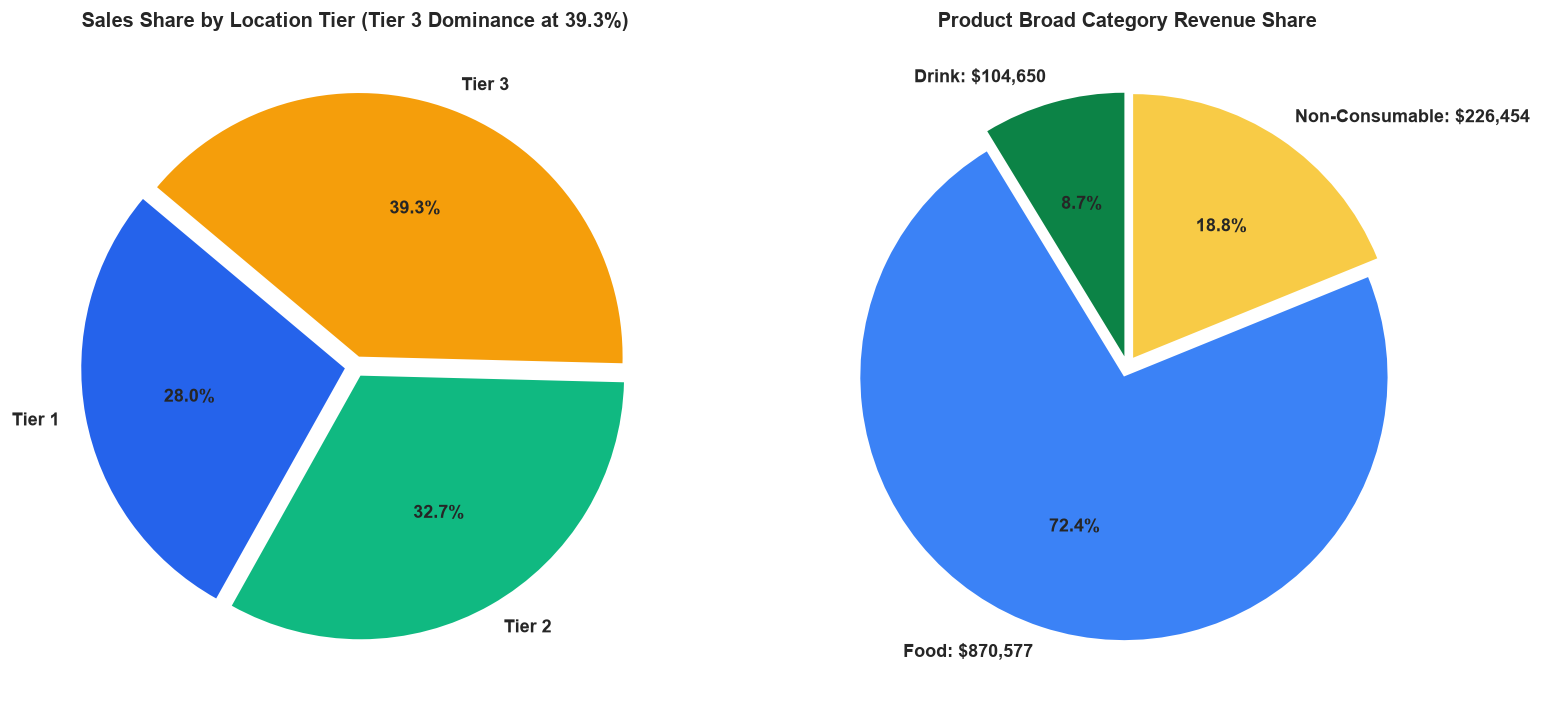

In [11]:
# Pie Charts Suite
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Location Tiers Pie Chart
tier_sales = clean_df.groupby('Outlet Location Type')['Sales'].sum()
axes[0].pie(tier_sales, labels=tier_sales.index, autopct='%1.1f%%', colors=['#2563EB', '#10B981', '#F59E0B'],
            explode=(0.04, 0.04, 0.04), startangle=140, textprops={'fontweight': 'bold', 'fontsize': 11})
axes[0].set_title('Sales Share by Location Tier (Tier 3 Dominance at 39.3%)', fontsize=12, fontweight='bold')

# 2. Product Broad Category Pie Chart
cat_s = clean_df.groupby('Product Category')['Sales'].sum()
axes[1].pie(cat_s, labels=[f"{k}: ${v:,.0f}" for k, v in cat_s.items()], autopct='%1.1f%%',
            colors=['#0C8346', '#3B82F6', '#F8CB46'], explode=(0.04, 0.04, 0.04), startangle=90, textprops={'fontweight': 'bold', 'fontsize': 11})
axes[1].set_title('Product Broad Category Revenue Share', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 🍩 B. Circular Donut Charts (Formats & Operational KPIs)

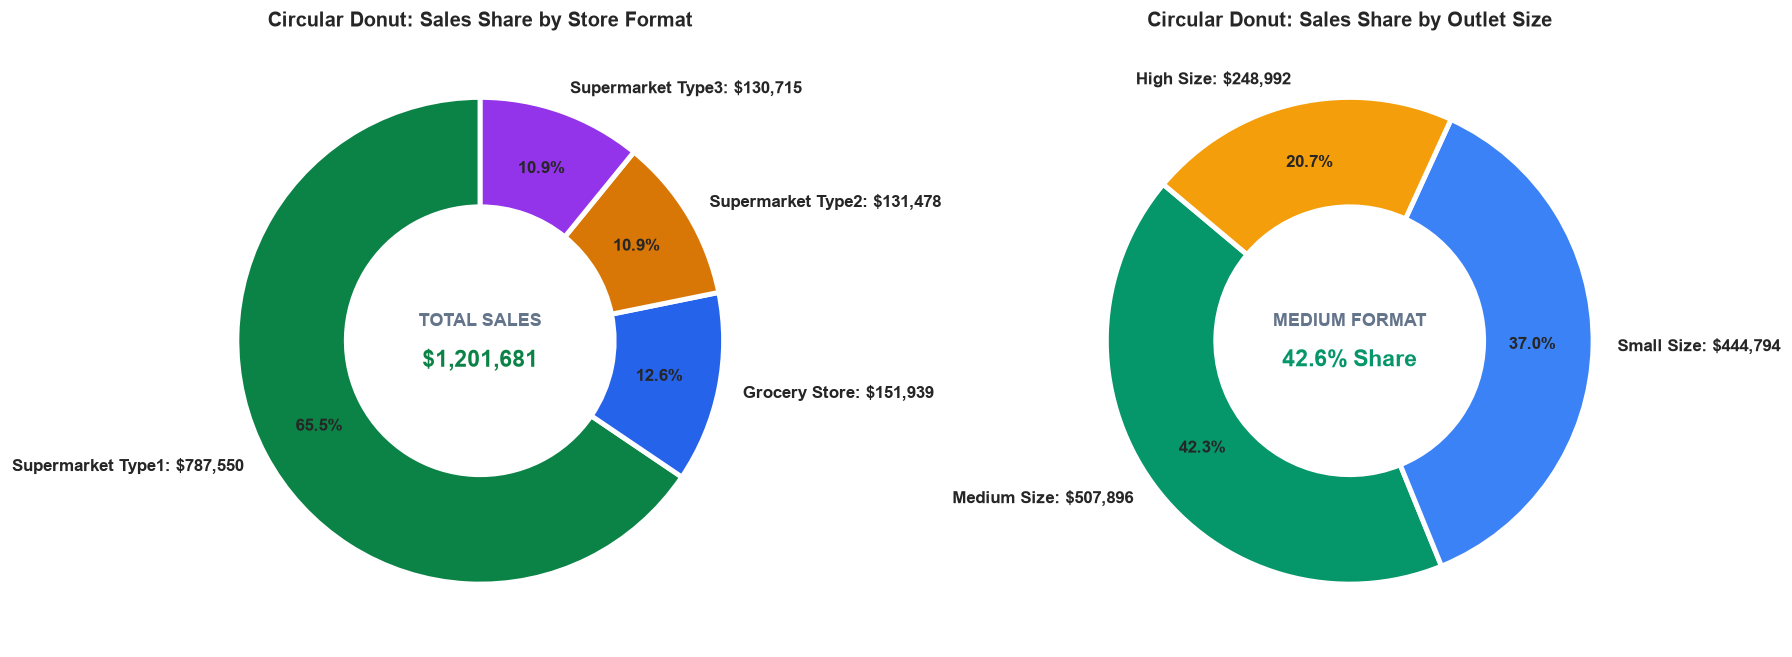

In [12]:
# Circular Donut Charts with Centered KPI Metrics
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# 1. Circular Donut: Outlet Type Sales
outlet_type_sales = clean_df.groupby('Outlet Type')['Sales'].sum().sort_values(ascending=False)
axes[0].pie(outlet_type_sales, labels=[f"{k}: ${v:,.0f}" for k, v in outlet_type_sales.items()],
            autopct='%1.1f%%', pctdistance=0.75, startangle=90, colors=['#0C8346', '#2563EB', '#D97706', '#9333EA'],
            wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 3}, textprops={'fontweight': 'bold'})
axes[0].text(0, 0.08, 'TOTAL SALES', ha='center', va='center', fontsize=11, fontweight='bold', color='#64748B')
axes[0].text(0, -0.08, f"${clean_df['Sales'].sum():,.0f}", ha='center', va='center', fontsize=14, fontweight='bold', color='#0C8346')
axes[0].set_title('Circular Donut: Sales Share by Store Format', fontsize=12, fontweight='bold')

# 2. Circular Donut: Outlet Physical Size
size_sales = clean_df.groupby('Outlet Size')['Sales'].sum().sort_values(ascending=False)
axes[1].pie(size_sales, labels=[f"{k} Size: ${v:,.0f}" for k, v in size_sales.items()],
            autopct='%1.1f%%', pctdistance=0.75, startangle=140, colors=['#059669', '#3B82F6', '#F59E0B'],
            wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 3}, textprops={'fontweight': 'bold'})
axes[1].text(0, 0.08, 'MEDIUM FORMAT', ha='center', va='center', fontsize=11, fontweight='bold', color='#64748B')
axes[1].text(0, -0.08, '42.6% Share', ha='center', va='center', fontsize=14, fontweight='bold', color='#059669')
axes[1].set_title('Circular Donut: Sales Share by Outlet Size', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 📊 C. Bar Charts (Comparative & Ranking Analysis)

C:\Users\sn740\AppData\Local\Temp\ipykernel_18908\2344948423.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=out_sales.index, y=out_sales.values, ax=axes[1], palette='Blues_r')


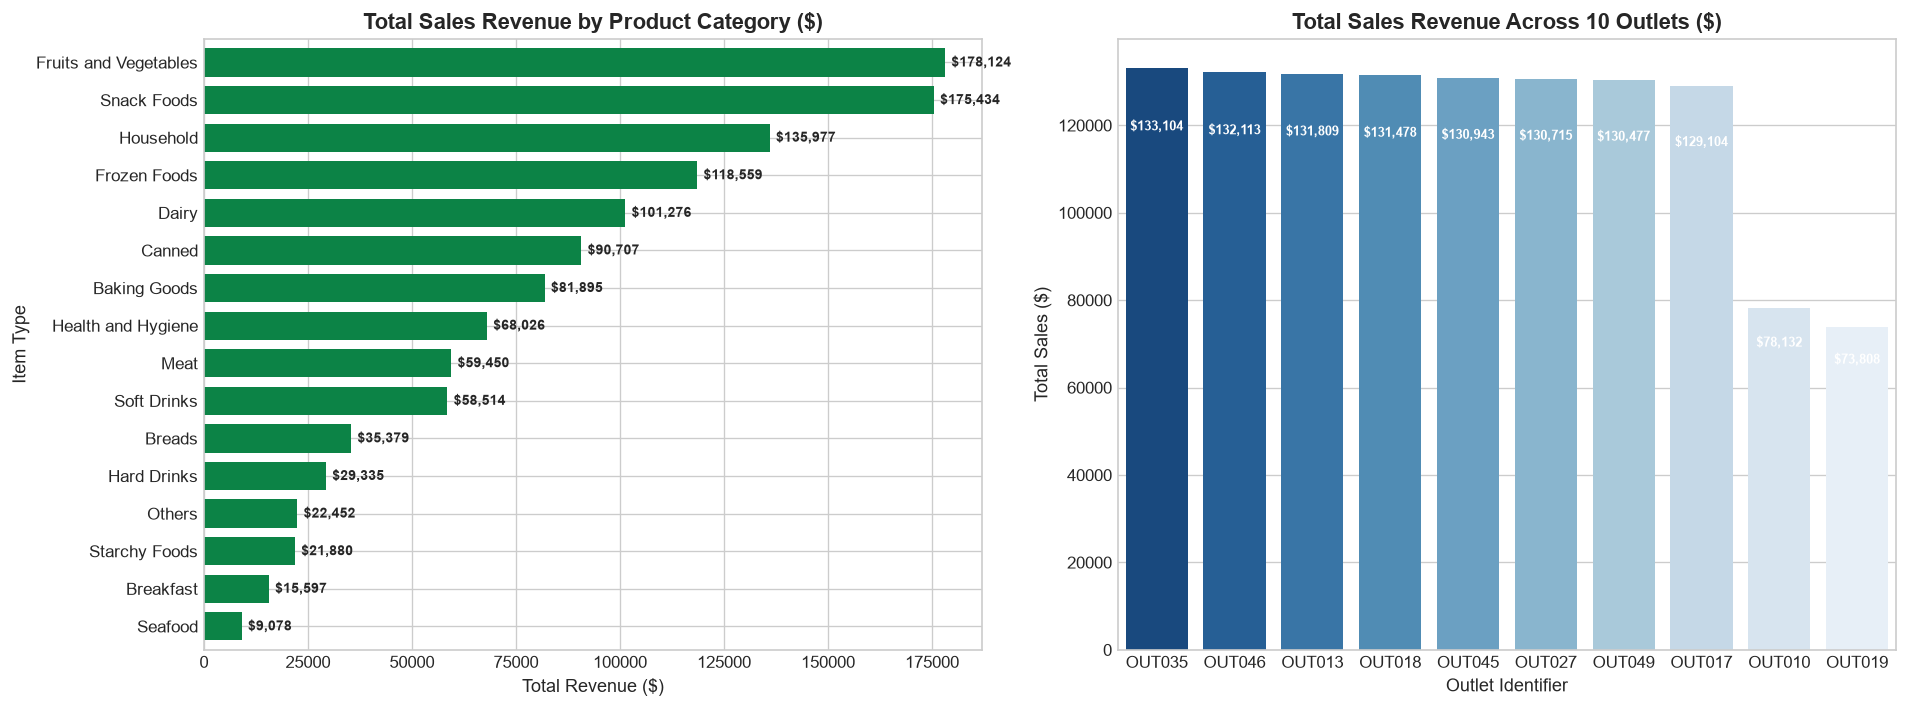

In [13]:
# Bar Charts Suite
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Horizontal Bar Chart: Category Total Sales
cat_sales = clean_df.groupby('Item Type')['Sales'].sum().sort_values(ascending=True)
ax1 = cat_sales.plot(kind='barh', ax=axes[0], color='#0C8346', width=0.75)
axes[0].set_title('Total Sales Revenue by Product Category ($)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Revenue ($)')
for p in ax1.patches:
    w = p.get_width()
    ax1.annotate(f"${w:,.0f}", (w + 1500, p.get_y() + p.get_height() / 2.), va='center', fontsize=8.5, fontweight='bold')

# 2. Bar Chart: Outlet Total Sales Comparison
out_sales = clean_df.groupby('Outlet Identifier')['Sales'].sum().sort_values(ascending=False)
ax2 = sns.barplot(x=out_sales.index, y=out_sales.values, ax=axes[1], palette='Blues_r')
axes[1].set_title('Total Sales Revenue Across 10 Outlets ($)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Total Sales ($)')
for p in ax2.patches:
    ax2.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.show()


---
## 💡 Objective 3 & 4: Performance Drivers & Strategic Decision Making
- Pearson correlation analysis verifying feature impact.
- Pareto (80/20) analysis curve identifying revenue-driving SKUs.
- Executive management decision framework.


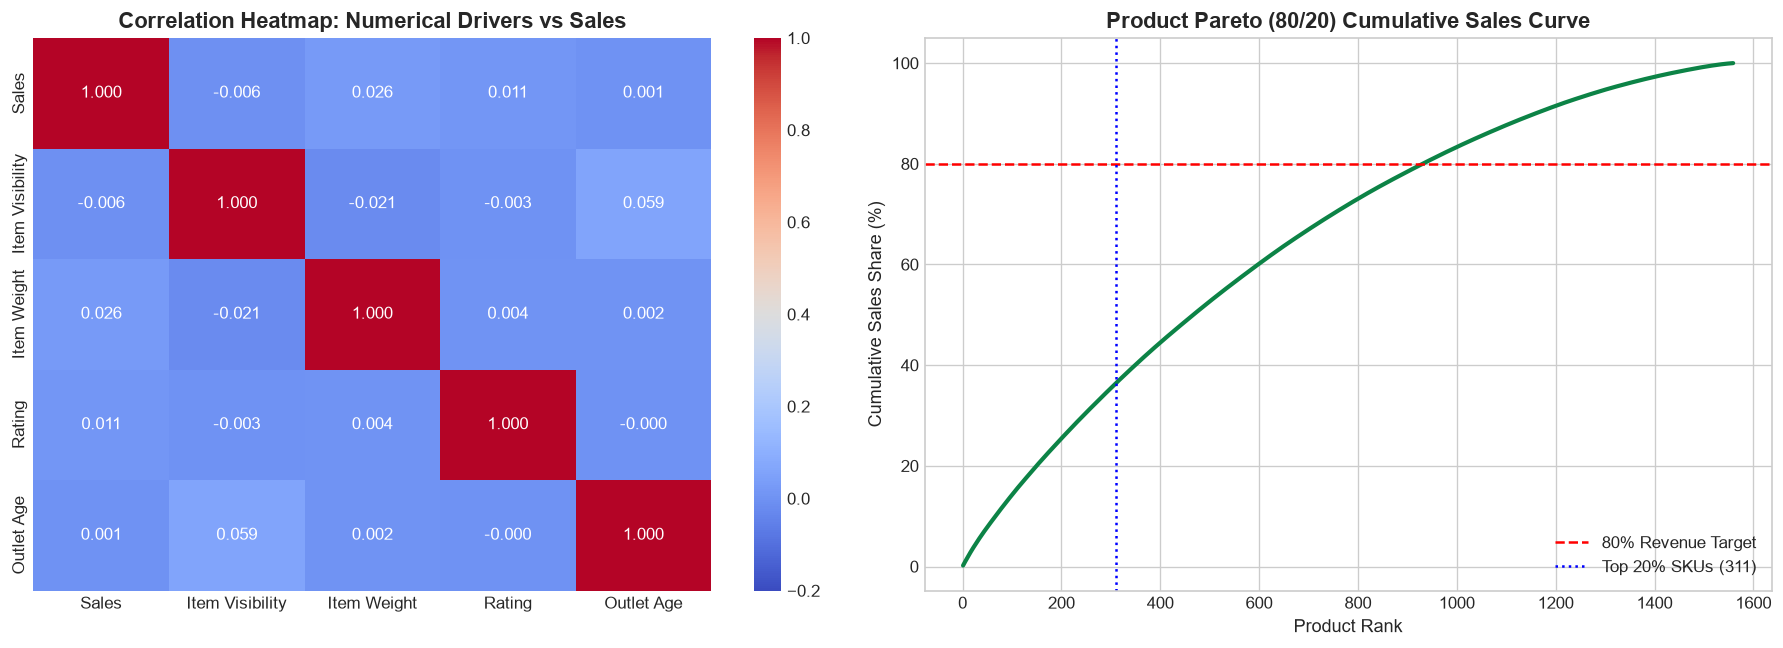

In [14]:
# Correlation Matrix & Pareto Analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Correlation Heatmap
corr_matrix = clean_df[['Sales', 'Item Visibility', 'Item Weight', 'Rating', 'Outlet Age']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', vmin=-0.2, vmax=1.0, ax=axes[0])
axes[0].set_title('Correlation Heatmap: Numerical Drivers vs Sales')

# 2. Product Pareto Curve
sku_sales = clean_df.groupby('Item Identifier')['Sales'].sum().sort_values(ascending=False).reset_index()
sku_sales['Cumulative_Share_%'] = (sku_sales['Sales'].cumsum() / sku_sales['Sales'].sum()) * 100
sku_sales['Rank'] = range(1, len(sku_sales) + 1)
top_20_count = int(len(sku_sales) * 0.20)

axes[1].plot(sku_sales['Rank'], sku_sales['Cumulative_Share_%'], color='#0C8346', lw=2.5)
axes[1].axhline(80, color='red', linestyle='--', label='80% Revenue Target')
axes[1].axvline(top_20_count, color='blue', linestyle=':', label=f'Top 20% SKUs ({top_20_count})')
axes[1].set_title('Product Pareto (80/20) Cumulative Sales Curve')
axes[1].set_xlabel('Product Rank')
axes[1].set_ylabel('Cumulative Sales Share (%)')
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 🎯 Executive Recommendations
1. 🏬 **Replicate Supermarket Dark-Store Format in Tier 2/3 Clusters:** Capitalize on OUT027's volume leadership.
2. 📱 **Fix Zero-Visibility Algorithm Blindspots:** Ensure all active catalog items are indexed.
3. 📦 **High-Velocity Cross-Merchandising:** Bundle Snack Foods with Beverages and Dairy with Breakfast items.
4. ❄️ **Cold-Chain Logistics Reinforcement:** Protect Produce, Dairy, and Frozen Foods ($398K combined revenue) from spoilage.
5. 🌟 **Quality Interventions:** Highlight 4.5+ star items with promotional badges; audit suppliers of items under 3.5 stars.
